# 04 · Feature engineering — first batch

## Imports

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load batch

In [2]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if not files:
    raise FileNotFoundError('Collect a batch in notebook 01 first.')
with files[0].open() as file:
    batch = json.load(file)
df = pd.DataFrame(batch['data'])
print(f"Group {GROUP} | batch {batch['batch_number']} | {len(df):,} rows")


Group 4 | batch 0 | 73,784 rows


## Create features

In [3]:
features = df.copy()
features['total_rooms'] = features['bed'] + features['bath']
features['size_per_room'] = features['house_size'] / features['total_rooms'].where(features['total_rooms'] > 0)
features['previous_sale_year'] = pd.to_datetime(features['prev_sold_date'], errors='coerce').dt.year
features['house_size_squared'] = features['house_size'] ** 2
columns = ['bed', 'bath', 'house_size', 'total_rooms', 'size_per_room', 'previous_sale_year', 'house_size_squared']
display(features[columns].head())
display(features[columns].describe(percentiles=[.01, .5, .99]).T)


,bed,bath,house_size,total_rooms,size_per_room,previous_sale_year,house_size_squared
0,4.0,2.0,1617.0,6.0,269.500000,1999,2614689.0
1,3.0,2.0,1850.0,5.0,370.000000,2015,3422500.0
2,3.0,2.0,1620.0,5.0,324.000000,2011,2624400.0
3,4.0,2.0,1735.0,6.0,289.166667,2014,3010225.0
4,3.0,2.0,2005.0,5.0,401.000000,2007,4020025.0


,count,mean,std,min,1%,50%,99%,max
bed,73784.0,3.433183e+00,1.122195e+00,1.0,2.000000e+00,3.0,6.0,1.900000e+02
bath,73784.0,2.262604e+00,9.048626e-01,1.0,1.000000e+00,2.0,4.0,1.630000e+02
house_size,73784.0,2.109465e+03,8.693199e+03,1500.0,1.500000e+03,1837.0,3896.0,1.560780e+06
total_rooms,73784.0,5.695788e+00,1.802899e+00,2.0,3.000000e+00,5.0,10.0,3.530000e+02
size_per_room,73784.0,3.988892e+02,2.739112e+03,104.0,2.222857e+02,336.8,666.0,2.675235e+05
previous_sale_year,73784.0,2.012419e+03,9.082626e+00,1904.0,1.984000e+03,2016.0,2022.0,2.026000e+03
house_size_squared,73784.0,8.002052e+07,9.499159e+09,2250000.0,2.250000e+06,3374569.0,15178816.0,2.436034e+12


## Check relationships

,price,total_rooms,size_per_room
price,1.000000,0.082793,-0.044248
total_rooms,0.082793,1.000000,-0.032911
size_per_room,-0.044248,-0.032911,1.000000


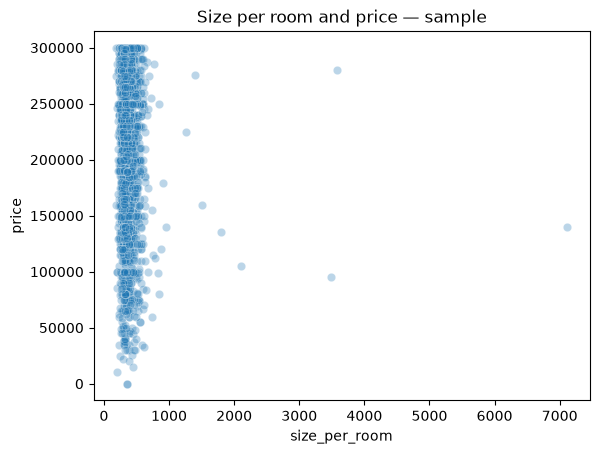

In [4]:
display(features[['price', 'total_rooms', 'size_per_room']].corr())
plot = features[['price', 'size_per_room']].dropna().sample(n=min(3000, len(features[['price', 'size_per_room']].dropna())), random_state=42)
sns.scatterplot(data=plot, x='size_per_room', y='price', alpha=.3)
plt.title('Size per room and price — sample')
plt.show()


Features use input values only. Squared terms are tested in the model pipeline; verify the sale date is known at prediction time.
